# 02 - Feature engineering, model selection and evaluation
The production training run is `python -m heart.train` (logged to MLflow). This notebook explains the choices and reads the results back from MLflow.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
%matplotlib inline
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
from heart import config, data
import json, mlflow
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from heart import train as T
from heart.features import build_preprocessor, feature_names
plt.switch_backend('module://matplotlib_inline.backend_inline')  # heart.train forces Agg; restore inline

In [2]:
df = data.load_clean()
X_tr, X_te, y_tr, y_te = T.split(df)
print(X_tr.shape, X_te.shape, y_tr.mean().round(3), y_te.mean().round(3))

(241, 13) (61, 13) 0.456 0.459


## 1. Feature engineering / preprocessing (`heart/features.py`)
| Group | Columns | Treatment |
|---|---|---|
| Continuous | age, trestbps, chol, thalach, oldpeak | median imputation, standard scaling |
| Engineered | `pct_max_hr` = thalach / (220 - age); `st_depression_with_angina` = oldpeak x exang | same as continuous |
| Categorical | sex, cp, fbs, restecg, exang, slope, ca, thal | most-frequent imputation, one-hot (unknown ignored) |

Everything lives inside one scikit-learn `Pipeline`, so the exact same transformation is applied in training, CV, the API and the container.

In [3]:
pre = build_preprocessor().fit(X_tr)
Z = pre.transform(X_tr)
print('transformed shape:', Z.shape)
print(feature_names(pre))

transformed shape: (241, 30)
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'pct_max_hr', 'st_depression_with_angina', 'sex_0.0', 'sex_1.0', 'cp_0.0', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'fbs_0.0', 'fbs_1.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'exang_0.0', 'exang_1.0', 'slope_0.0', 'slope_1.0', 'slope_2.0', 'ca_0.0', 'ca_1.0', 'ca_2.0', 'ca_3.0', 'thal_1.0', 'thal_2.0', 'thal_3.0']


## 2. Baseline comparison with default hyper-parameters (5-fold stratified CV, training split only)

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=config.RANDOM_STATE)
models = {'dummy (majority class)': DummyClassifier(strategy='most_frequent'),
          'logistic_regression': LogisticRegression(max_iter=2000),
          'random_forest': RandomForestClassifier(random_state=42),
          'gradient_boosting': GradientBoostingClassifier(random_state=42)}
rows = {}
for name, est in models.items():
    r = cross_validate(T.make_pipeline(est), X_tr, y_tr, cv=cv, scoring=T.SCORING)
    rows[name] = {m: f"{r['test_'+m].mean():.3f} +/- {r['test_'+m].std():.3f}" for m in T.SCORING}
pd.DataFrame(rows).T

,accuracy,precision,recall,f1,roc_auc
dummy (majority class),0.544 +/- 0.004,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000
logistic_regression,0.838 +/- 0.042,0.851 +/- 0.088,0.800 +/- 0.094,0.818 +/- 0.052,0.905 +/- 0.036
random_forest,0.851 +/- 0.036,0.859 +/- 0.077,0.818 +/- 0.076,0.833 +/- 0.038,0.909 +/- 0.032
gradient_boosting,0.813 +/- 0.047,0.817 +/- 0.104,0.791 +/- 0.102,0.794 +/- 0.050,0.888 +/- 0.053


The dummy model confirms the scale of the task (ROC-AUC 0.5). All real models are clearly better; logistic regression is already competitive, which is typical for a small, mostly-linear clinical dataset.

## 3. Hyper-parameter tuning and final selection
Grid search (5-fold, ROC-AUC) inside a *nested* CV loop gives an estimate that includes the tuning step. The tuned models were then scored once on the hold-out test set. Results come straight from MLflow:

In [5]:
mlflow.set_tracking_uri(config.MLFLOW_URI)
exp = mlflow.get_experiment_by_name(config.MLFLOW_EXPERIMENT)
runs = mlflow.search_runs([exp.experiment_id], filter_string="tags.mlflow.parentRunId != ''", order_by=['start_time DESC'])
runs = runs.drop_duplicates('params.model')
cols = ['params.model'] + [c for c in runs.columns if c.startswith('metrics.cv_') and c.endswith('_mean')] + [c for c in runs.columns if c.startswith('metrics.test_')]
runs[cols].rename(columns=lambda c: c.replace('metrics.','').replace('params.','')).set_index('model').round(3)

,cv_recall_mean,cv_precision_mean,cv_f1_mean,cv_accuracy_mean,cv_roc_auc_mean,test_precision,test_roc_auc,test_f1,test_accuracy,test_recall
model,,,,,,,,,,
gradient_boosting,0.809,0.830,0.812,0.830,0.900,0.818,0.879,0.720,0.770,0.643
random_forest,0.791,0.845,0.808,0.830,0.910,0.826,0.894,0.745,0.787,0.679
logistic_regression,0.809,0.858,0.827,0.846,0.907,0.846,0.918,0.815,0.836,0.786


In [6]:
print(json.dumps(json.loads((config.METADATA_PATH).read_text()), indent=2)[:1500])

{
  "model_name": "logistic_regression",
  "model_version": "1.0.0-202610181958",
  "trained_at": "2026-10-18T19:58:54+00:00",
  "features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
  ],
  "target": "target",
  "best_params": {
    "model__C": 0.1,
    "model__class_weight": null
  },
  "nested_cv_metrics": {
    "accuracy": {
      "mean": 0.8463,
      "std": 0.0317
    },
    "precision": {
      "mean": 0.8576,
      "std": 0.0708
    },
    "recall": {
      "mean": 0.8091,
      "std": 0.0881
    },
    "f1": {
      "mean": 0.8266,
      "std": 0.0381
    },
    "roc_auc": {
      "mean": 0.9075,
      "std": 0.0393
    }
  },
  "test_metrics": {
    "accuracy": 0.8361,
    "precision": 0.8462,
    "recall": 0.7857,
    "f1": 0.8148,
    "roc_auc": 0.9177
  },
  "data_md5": "d342b61dc8ecd05c87dec66d2a095d12",
  "n_train": 241,
  "n_test": 61,
  "python": "3

## 4. Evaluation of the selected model on the hold-out test set

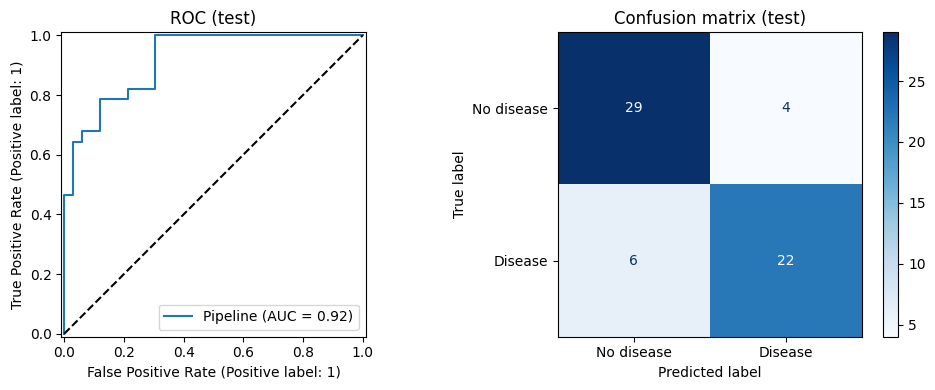

              precision    recall  f1-score   support

  no disease       0.83      0.88      0.85        33
     disease       0.85      0.79      0.81        28

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



In [7]:
import joblib
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay, classification_report, precision_recall_curve
model = joblib.load(config.MODEL_PATH)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_estimator(model, X_te, y_te, ax=ax[0]); ax[0].plot([0,1],[0,1],'k--'); ax[0].set_title('ROC (test)')
ConfusionMatrixDisplay.from_estimator(model, X_te, y_te, ax=ax[1], cmap='Blues', display_labels=['No disease','Disease']); ax[1].set_title('Confusion matrix (test)')
plt.tight_layout(); plt.show()
print(classification_report(y_te, model.predict(X_te), target_names=['no disease','disease']))

## 5. Operating point
For screening, a missed case (false negative) is costlier than a false alarm. The curve shows what lowering the threshold would buy.

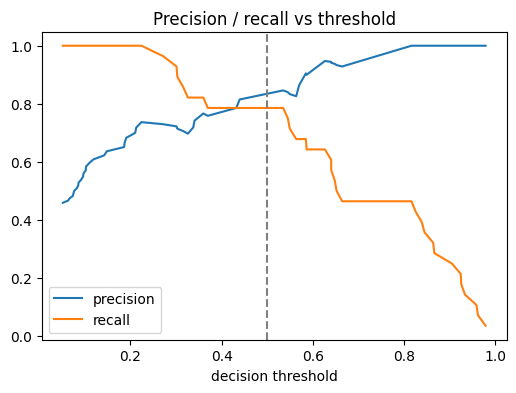

t=0.3: precision=0.722 recall=0.929
t=0.4: precision=0.786 recall=0.786
t=0.5: precision=0.846 recall=0.786


In [8]:
p = model.predict_proba(X_te)[:, 1]
prec, rec, thr = precision_recall_curve(y_te, p)
plt.figure(figsize=(6,4)); plt.plot(thr, prec[:-1], label='precision'); plt.plot(thr, rec[:-1], label='recall')
plt.axvline(0.5, color='gray', ls='--'); plt.xlabel('decision threshold'); plt.legend(); plt.title('Precision / recall vs threshold'); plt.show()
for t in (0.3, 0.4, 0.5):
    pred = (p >= t).astype(int)
    print(f't={t}: precision={(pred[y_te==1].sum()/max(pred.sum(),1)):.3f} recall={pred[y_te==1].mean():.3f}')

The service uses 0.5 by default; a deployment for screening could expose the threshold as configuration.